# YZM 411 – Gövde / Yelek Etiketleyici

Colab'da ve kendi bilgisayarınızda (Jupyter / VS Code) çalışır.
**Colab'da** etiketleyici hücrenin içinde açılır. **Yerelde** ise ayrı bir OpenCV penceresi açılır.

1. **Yollar** hücresine görüntü klasörünüzün yolunu (`path`) yazın.
   Colab'da görüntüleri **Google Drive'a** koyun. Yolu soldaki dosya panelinde klasöre sağ tıklayıp *Yolu kopyala* ile alabilirsiniz (`/content/drive/MyDrive/...`).
   Dosyaları `/content`'e doğrudan yüklerseniz oturum kapanınca görüntüler de etiketler de silinir.
2. Hücreleri sırayla çalıştırın.
3. Bitince **Kontrol** hücresiyle kutuları defterin içinde görüp eksikleri kontrol edin.

**Kısayollar** (Colab'da önce resme bir kez tıklayın; düğmeler de aynı işi görür)

| Tuş | İşlev |
|---|---|
| Sürükle | Aktif etiketle kutu çiz |
| Tıkla | Kutuyu seç |
| `g` / `y` | Aktif etiket: gövde / yelek |
| `s` | Seçili gövdeyi "karar verilecek kişi" yap (ilk çizilen gövde otomatik seçilir) |
| `x` | Seçili kutuyu sil |
| `u` | Son kutuyu geri al |
| `1` `2` `3` `4` | Doğru sınıf: Yelek giyili / Yelek var, giyili değil / Yelek yok / Belirsiz (`0` temizler) |
| `n` / `b` | Sonraki / önceki görüntü |
| `q` / `ESC` | (Yalnız yerel pencere) kaydet ve çık |

**Çıktılar:** `kutular.csv` (goruntu, etiket, x1, y1, x2, y2, secilen_kisi; piksel, sol üst köşe başlangıç), `goruntuler.csv` (boyut, doğru sınıf, kutu sayıları) ve `etiketler.json`. Her değişiklik otomatik kaydedilir. Defter yeniden çalıştırılınca kaldığı yerden devam eder.


In [18]:
# ======================= YOLLAR: buraya kendi yollarinizi yazin =======================
path = r"/content/drive/MyDrive/Ödevler/computer-vision/yelek-tespiti/veriseti/kontrol"   # etiketlenecek goruntulerin klasoru

resize_path = None   # Orn. "/content/drive/MyDrive/yelek_veri/secilen_20_1024"
                     # Verirseniz once uzun kenari 1024'u asanlar INTER_AREA ile kucultulur,
                     # sonra bu klasor etiketlenir. Etiketlemeden ONCE kucultun.
out_path = r"/content/drive/MyDrive/Ödevler/computer-vision/yelek-tespiti/veriseti/kontrol-etiketli"      # None: etiket dosyalari (json/csv) etiketlenen klasore yazilir

In [9]:
# Colab'da Google Drive'i baglar (yerel Jupyter'da hicbir sey yapmaz)
import sys
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
import base64
import csv
import json
import os
import shutil
import sys
import time
import unicodedata
from pathlib import Path

import cv2
import numpy as np
from IPython.display import HTML, JSON, display

COLAB = "google.colab" in sys.modules
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
MAX_SIDE = 1024
CLASSES = {1: "Yelek giyili", 2: "Yelek var, giyili değil", 3: "Yelek yok", 4: "Belirsiz"}


# ============================================================ dosya yardimcilari
def imread_u(path):
    """Turkce karakterli yollarda da calisan imread."""
    data = np.fromfile(str(path), dtype=np.uint8)
    return cv2.imdecode(data, cv2.IMREAD_COLOR) if data.size else None


def imwrite_u(path, img):
    ext = Path(path).suffix.lower()
    params = [cv2.IMWRITE_JPEG_QUALITY, 95] if ext in (".jpg", ".jpeg") else []
    ok, buf = cv2.imencode(ext, img, params)
    if not ok:
        raise IOError(f"Yazilamadi: {path}")
    buf.tofile(str(path))


def _nfc(s):
    return unicodedata.normalize("NFC", s).casefold()


def _ascii(s):
    s = unicodedata.normalize("NFKD", s.replace("ı", "i").replace("İ", "I"))
    return "".join(ch for ch in s if not unicodedata.combining(ch)).casefold()


def yolu_coz(yol):
    """Yolu parca parca arar; Turkce karakter kodlamasi (NFC/NFD), buyuk/kucuk harf ve
    s/ş, i/ı gibi farklari tolere eder. Bulamazsa nerede koptugunu ve o klasorun
    icindekileri yazdirir, None dondurur."""
    p = Path(str(yol).strip().strip('"').strip("'")).expanduser()
    if p.exists():
        return p
    cur = Path(p.parts[0])
    for part in p.parts[1:]:
        if (cur / part).exists():
            cur = cur / part
            continue
        try:
            icerik = sorted(os.listdir(cur))
        except OSError:
            icerik = []
        eslesen = ([c for c in icerik if _nfc(c) == _nfc(part)]
                   or [c for c in icerik if _ascii(c) == _ascii(part)])
        if eslesen:
            cur = cur / eslesen[0]
            continue
        print(f"BULUNAMADI: '{part}'\n  Aranan klasor: {cur}")
        if str(p).startswith("/content/drive") and not Path("/content/drive/MyDrive").exists():
            print("  Drive bagli degil: once 'Drive baglantisi' hucresini calistirin.")
        elif icerik:
            print("  Bu klasorun icindekiler:")
            for c in icerik[:60]:
                print("   -", c)
        return None
    print(f"Yol su sekilde bulundu: {cur}")
    return cur


def list_images(folder):
    return sorted(p for p in Path(folder).iterdir()
                  if p.is_file() and p.suffix.lower() in IMG_EXTS)


def resize_folder(src, dst):
    """Uzun kenari 1024'u asanlari INTER_AREA ile kucultur, digerlerini kopyalar.
    Hedefte zaten olan dosyalara dokunmaz (hucre tekrar calisirsa)."""
    src, dst = Path(src).resolve(), Path(dst).resolve()
    if src == dst:
        raise ValueError("resize_path, path ile ayni klasor olamaz.")
    dst.mkdir(parents=True, exist_ok=True)
    images = list_images(src)
    if not images:
        raise FileNotFoundError(f"Kaynak klasorde goruntu yok: {src}")
    for p in images:
        out = dst / p.name
        if out.exists():
            print(f"  zaten var, atlandi: {p.name}")
            continue
        img = imread_u(p)
        if img is None:
            print(f"  ATLANDI (okunamadi): {p.name}")
            continue
        h, w = img.shape[:2]
        if max(h, w) > MAX_SIDE:
            s = MAX_SIDE / max(h, w)
            nw, nh = max(1, round(w * s)), max(1, round(h * s))
            imwrite_u(out, cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA))
            print(f"  kucultuldu: {p.name}  {w}x{h} -> {nw}x{nh}")
        else:
            shutil.copy2(p, out)
            print(f"  kopyalandi: {p.name}  {w}x{h} (kucultme gerekmedi)")
    return dst


# ============================================================ kayit
def bos_kayit():
    return {"genislik": None, "yukseklik": None, "dogru_sinif": None, "kutular": []}


def yukle(out_dir):
    p = Path(out_dir) / "etiketler.json"
    if p.exists():
        with open(p, encoding="utf-8") as f:
            print(f"Onceki etiketler yuklendi: {p}")
            return json.load(f)
    return {}


def kaydet(data, out_dir):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    jp = out_dir / "etiketler.json"
    tmp = out_dir / "etiketler.json.tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False, indent=2)
    try:
        os.replace(tmp, jp)
    except OSError:  # bazi ag/Drive dosya sistemlerinde
        shutil.copyfile(tmp, jp)
        tmp.unlink(missing_ok=True)

    with open(out_dir / "kutular.csv", "w", newline="", encoding="utf-8-sig") as f:
        w = csv.writer(f)
        w.writerow(["goruntu", "etiket", "x1", "y1", "x2", "y2", "secilen_kisi"])
        for name in sorted(data):
            for b in data[name]["kutular"]:
                w.writerow([name, b["etiket"], b["x1"], b["y1"], b["x2"], b["y2"],
                            int(bool(b.get("secilen_kisi")))])
    with open(out_dir / "goruntuler.csv", "w", newline="", encoding="utf-8-sig") as f:
        w = csv.writer(f)
        w.writerow(["goruntu", "genislik", "yukseklik", "dogru_sinif", "govde_sayisi", "yelek_sayisi"])
        for name in sorted(data):
            e = data[name]
            ks = e["kutular"]
            w.writerow([name, e.get("genislik"), e.get("yukseklik"), e.get("dogru_sinif") or "",
                        sum(b["etiket"] == "govde" for b in ks),
                        sum(b["etiket"] == "yelek" for b in ks)])


def ilk_etiketsiz(images, data):
    for i, p in enumerate(images):
        if not data.get(p.name, {}).get("kutular"):
            return i
    return 0


# ============================================================ Colab: hucre icinde calisan etiketleyici
WIDGET_HTML = r"""
<div id="yzm-root" style="font-family:system-ui,sans-serif;font-size:13px;color:#222;background:#fff;padding:6px;">
  <style>
    #yzm-root button{margin:2px;padding:4px 8px;border:1px solid #999;border-radius:4px;background:#f4f4f4;cursor:pointer;font-size:13px}
    #yzm-root button.on{background:#1f3864;color:#fff;border-color:#1f3864}
    #yzm-root .grp{display:inline-block;margin-right:10px}
  </style>
  <div>
    <span class="grp">Etiket:
      <button data-k="g" id="b-govde">Gövde (g)</button><button data-k="y" id="b-yelek">Yelek (y)</button></span>
    <span class="grp"><button data-k="b">◀ Önceki (b)</button><button data-k="n">Sonraki ▶ (n)</button></span>
    <span class="grp"><button data-k="s">Seçili gövde = karar verilecek kişi (s)</button>
      <button data-k="x">Seçili kutuyu sil (x)</button><button data-k="u">Son kutuyu geri al (u)</button>
      <button data-k="escape">Seçimi kaldır (Esc)</button></span>
  </div>
  <div>Doğru sınıf:
    <button data-k="1">1 Yelek giyili</button><button data-k="2">2 Yelek var, giyili değil</button>
    <button data-k="3">3 Yelek yok</button><button data-k="4">4 Belirsiz</button><button data-k="0">0 Temizle</button>
    <label style="margin-left:12px"><input type="checkbox" id="yzm-loupe" checked> Büyüteç</label>
  </div>
  <div id="yzm-status" style="margin:4px 0;font-weight:600"></div>
  <div id="yzm-msg" style="min-height:18px;color:#b45309"></div>
  <canvas id="yzm-canvas" tabindex="0" style="max-width:100%;height:auto;cursor:crosshair;border:1px solid #888;outline:none;display:block"></canvas>
  <div style="color:#666;margin-top:4px">Sürükle: yeni kutu · Tıkla: kutu seç · Seçili kutunun kenarını ya da köşesini sürükle: boyutlandır ·
    Esc: seçimi kaldır · Kısayollar için önce resme bir kez tıklayın · Her değişiklik otomatik kaydedilir.</div>
</div>
<script>
(function () {
  const START = %START%;
  const COLORS = {govde: '#16a34a', yelek: '#f97316'};
  const CLASSES = {1: 'Yelek giyili', 2: 'Yelek var, giyili değil', 3: 'Yelek yok', 4: 'Belirsiz'};
  const root = document.getElementById('yzm-root');
  const canvas = root.querySelector('#yzm-canvas');
  const loupeBox = root.querySelector('#yzm-loupe');
  const ctx = canvas.getContext('2d');
  const img = new Image();
  // act: {mode:'new', x0,y0,x1,y1} ya da {mode:'resize', i, h:{l,r,t,b}, orig}
  let cur = null, label = 'govde', sel = null, act = null, mouse = null, reqId = 0, msgTimer = null;

  async function call(fn, args) {
    const r = await google.colab.kernel.invokeFunction(fn, args, {});
    return r.data['application/json'];
  }
  function msg(t, keep) {
    const m = root.querySelector('#yzm-msg');
    m.textContent = t || '';
    clearTimeout(msgTimer);
    if (t && !keep) msgTimer = setTimeout(() => { m.textContent = ''; }, 3000);
  }
  const boxes = () => (cur ? cur.entry.kutular : []);
  const sc = () => canvas.width / (canvas.clientWidth || canvas.width);   // 1 ekran pikseli = sc goruntu pikseli
  const clamp = (v, a, b) => Math.min(Math.max(v, a), b);

  function status() {
    if (!cur) return;
    const b = boxes();
    const ng = b.filter(x => x.etiket === 'govde').length, ny = b.length - ng;
    let t = `[${cur.i + 1}/${cur.n}] ${cur.name}  ${cur.w}×${cur.h}   ·   etiketli: ${cur.done}/${cur.n}` +
      `   ·   sınıf: ${cur.entry.dogru_sinif || '—'}   ·   gövde: ${ng}, yelek: ${ny}` +
      `   ·   aktif etiket: ${label === 'govde' ? 'GÖVDE' : 'YELEK'}`;
    if (sel !== null && b[sel]) {
      const s = b[sel];
      t += `   ·   seçili: ${s.etiket} (${s.x1}, ${s.y1}) – (${s.x2}, ${s.y2})`;
    }
    root.querySelector('#yzm-status').textContent = t;
    root.querySelector('#b-govde').classList.toggle('on', label === 'govde');
    root.querySelector('#b-yelek').classList.toggle('on', label === 'yelek');
    root.querySelectorAll('button[data-k]').forEach(btn => {
      const k = btn.dataset.k;
      if (k.length === 1 && '1234'.includes(k)) btn.classList.toggle('on', cur.entry.dogru_sinif === CLASSES[k]);
    });
  }

  function handlesOf(b) {
    const mx = (b.x1 + b.x2) / 2, my = (b.y1 + b.y2) / 2;
    return [[b.x1, b.y1], [mx, b.y1], [b.x2, b.y1], [b.x2, my], [b.x2, b.y2], [mx, b.y2], [b.x1, b.y2], [b.x1, my]];
  }

  function draw() {
    if (!cur) return;
    const s = sc();
    ctx.drawImage(img, 0, 0, cur.w, cur.h);
    const lw = Math.max(1, 2 * s);
    const fs = Math.round(13 * s);
    ctx.font = `bold ${fs}px sans-serif`;
    ctx.textBaseline = 'top';
    boxes().forEach((b, i) => {
      const c = COLORS[b.etiket];
      ctx.strokeStyle = c; ctx.lineWidth = b.secilen_kisi ? 2 * lw : lw;
      ctx.strokeRect(b.x1, b.y1, b.x2 - b.x1, b.y2 - b.y1);
      const tag = (b.etiket === 'govde' ? 'gövde' : 'yelek') + (b.secilen_kisi ? ' ★ seçilen kişi' : '');
      const tw = ctx.measureText(tag).width, th = fs + 4;
      let ty;
      if (b.etiket === 'govde') ty = (b.y1 - th >= 0) ? b.y1 - th : b.y1;
      else ty = (b.y2 + th <= cur.h) ? b.y2 : b.y2 - th;
      ctx.globalAlpha = 0.85; ctx.fillStyle = c; ctx.fillRect(b.x1, ty, tw + 6, th); ctx.globalAlpha = 1;
      ctx.fillStyle = '#000'; ctx.fillText(tag, b.x1 + 3, ty + 2);
    });
    // secili kutu: tutamaclar
    if (sel !== null && boxes()[sel]) {
      const b = boxes()[sel], hs = 8 * s;
      ctx.setLineDash([6 * s, 4 * s]); ctx.strokeStyle = '#fff'; ctx.lineWidth = s;
      ctx.strokeRect(b.x1, b.y1, b.x2 - b.x1, b.y2 - b.y1); ctx.setLineDash([]);
      handlesOf(b).forEach(([hx, hy]) => {
        ctx.fillStyle = '#fff'; ctx.fillRect(hx - hs / 2, hy - hs / 2, hs, hs);
        ctx.strokeStyle = '#000'; ctx.lineWidth = s; ctx.strokeRect(hx - hs / 2, hy - hs / 2, hs, hs);
      });
    }
    // cizilmekte olan kutu
    if (act && act.mode === 'new') {
      const x = Math.min(act.x0, act.x1), y = Math.min(act.y0, act.y1);
      const w = Math.abs(act.x1 - act.x0), h = Math.abs(act.y1 - act.y0);
      ctx.globalAlpha = 0.15; ctx.fillStyle = COLORS[label]; ctx.fillRect(x, y, w, h); ctx.globalAlpha = 1;
      ctx.strokeStyle = COLORS[label]; ctx.lineWidth = lw; ctx.strokeRect(x, y, w, h);
    }
    // kilavuz cizgiler (imlecin tam yeri)
    if (mouse) {
      ctx.beginPath();
      ctx.moveTo(mouse.x, 0); ctx.lineTo(mouse.x, cur.h); ctx.moveTo(0, mouse.y); ctx.lineTo(cur.w, mouse.y);
      ctx.strokeStyle = 'rgba(0,0,0,0.7)'; ctx.lineWidth = 3 * s; ctx.stroke();
      ctx.strokeStyle = '#fff'; ctx.lineWidth = s; ctx.stroke();
      if (loupeBox.checked) drawLoupe(s);
    }
  }

  // buyutec: imlecin cevresini 4 kat buyutup resmin karsi kosesinde gosterir
  function drawLoupe(s) {
    const Z = 4;
    const L = Math.min(Math.round(180 * s), Math.floor(Math.min(cur.w, cur.h) / 2));
    const src = L / Z;
    const sx = clamp(mouse.x - src / 2, 0, cur.w - src), sy = clamp(mouse.y - src / 2, 0, cur.h - src);
    const pad = 6 * s;
    const lx = (mouse.x < cur.w / 2) ? cur.w - L - pad : pad;
    const ly = (mouse.y < cur.h / 2) ? cur.h - L - pad - 18 * s : pad;
    ctx.save();
    ctx.imageSmoothingEnabled = false;
    ctx.drawImage(canvas, sx, sy, src, src, lx, ly, L, L);
    ctx.restore();
    ctx.strokeStyle = '#000'; ctx.lineWidth = 3 * s; ctx.strokeRect(lx, ly, L, L);
    ctx.strokeStyle = '#fff'; ctx.lineWidth = s; ctx.strokeRect(lx, ly, L, L);
    const t = `x ${Math.round(mouse.x)}, y ${Math.round(mouse.y)}`;
    ctx.font = `bold ${Math.round(12 * s)}px sans-serif`; ctx.textBaseline = 'top';
    const tw = ctx.measureText(t).width;
    ctx.fillStyle = 'rgba(0,0,0,0.75)'; ctx.fillRect(lx, ly + L, tw + 8 * s, 16 * s);
    ctx.fillStyle = '#fff'; ctx.fillText(t, lx + 4 * s, ly + L + 2 * s);
  }

  async function load(i) {
    const my = ++reqId;
    msg('Yükleniyor...', true);
    try {
      const d = await call('yzm411.get_image', [i]);
      if (my !== reqId) return;
      img.onload = () => {
        if (my !== reqId) return;
        cur = d; sel = null; act = null;
        canvas.width = d.w; canvas.height = d.h;
        draw(); status(); msg(d.warn || '', !!d.warn);
        canvas.focus();
      };
      img.src = d.src;
    } catch (e) { msg('Hata (görüntü yüklenemedi): ' + e, true); }
  }

  async function save() {
    status(); draw();
    try {
      const d = await call('yzm411.save', [cur.name, JSON.stringify(cur.entry)]);
      cur.done = d.done; status();
    } catch (e) { msg('KAYDEDİLEMEDİ: ' + e, true); }
  }

  function ensureSelected() {
    const g = boxes().filter(b => b.etiket === 'govde');
    if (g.length && !g.some(b => b.secilen_kisi)) g[0].secilen_kisi = true;
  }

  function boxAt(x, y) {
    let best = null, area = Infinity;
    boxes().forEach((b, i) => {
      if (x >= b.x1 && x <= b.x2 && y >= b.y1 && y <= b.y2) {
        const a = (b.x2 - b.x1) * (b.y2 - b.y1);
        if (a < area) { area = a; best = i; }
      }
    });
    return best;
  }

  // secili kutunun hangi kenarina/kosesine yakin? (tolerans ekranda ~8 piksel)
  function edgeHit(x, y) {
    if (sel === null || !boxes()[sel]) return null;
    const b = boxes()[sel], tol = 8 * sc();
    const inY = y >= b.y1 - tol && y <= b.y2 + tol, inX = x >= b.x1 - tol && x <= b.x2 + tol;
    const h = {l: inY && Math.abs(x - b.x1) <= tol, r: inY && Math.abs(x - b.x2) <= tol,
               t: inX && Math.abs(y - b.y1) <= tol, b: inX && Math.abs(y - b.y2) <= tol};
    if (h.l && h.r) { if (Math.abs(x - b.x1) <= Math.abs(x - b.x2)) h.r = false; else h.l = false; }
    if (h.t && h.b) { if (Math.abs(y - b.y1) <= Math.abs(y - b.y2)) h.b = false; else h.t = false; }
    return (h.l || h.r || h.t || h.b) ? h : null;
  }
  function cursorFor(h) {
    if (!h) return 'crosshair';
    if ((h.l && h.t) || (h.r && h.b)) return 'nwse-resize';
    if ((h.r && h.t) || (h.l && h.b)) return 'nesw-resize';
    return (h.l || h.r) ? 'ew-resize' : 'ns-resize';
  }

  function toImg(ev) {
    const r = canvas.getBoundingClientRect();  // kenarligi (border) haric tut
    const x = (ev.clientX - r.left - canvas.clientLeft) * canvas.width / canvas.clientWidth;
    const y = (ev.clientY - r.top - canvas.clientTop) * canvas.height / canvas.clientHeight;
    return [clamp(x, 0, canvas.width), clamp(y, 0, canvas.height)];
  }
  function overCanvas(ev) {
    const r = canvas.getBoundingClientRect();
    return ev.clientX >= r.left && ev.clientX <= r.right && ev.clientY >= r.top && ev.clientY <= r.bottom;
  }

  canvas.addEventListener('mousedown', ev => {
    if (!cur || ev.button !== 0) return;
    ev.preventDefault(); canvas.focus();
    const [x, y] = toImg(ev);
    const h = edgeHit(x, y);
    if (h) act = {mode: 'resize', i: sel, h, orig: Object.assign({}, boxes()[sel])};
    else act = {mode: 'new', x0: x, y0: y, x1: x, y1: y};
    draw();
  });
  window.addEventListener('mousemove', ev => {
    if (!cur) return;
    const [x, y] = toImg(ev);
    mouse = (act || overCanvas(ev)) ? {x, y} : null;
    if (act && act.mode === 'new') { act.x1 = x; act.y1 = y; }
    else if (act && act.mode === 'resize') {
      const b = boxes()[act.i];
      if (act.h.l) b.x1 = Math.round(x);
      if (act.h.r) b.x2 = Math.round(x);
      if (act.h.t) b.y1 = Math.round(y);
      if (act.h.b) b.y2 = Math.round(y);
      status();
    } else canvas.style.cursor = cursorFor(edgeHit(x, y));
    draw();
  });
  canvas.addEventListener('mouseleave', () => { if (!act) { mouse = null; draw(); } });
  window.addEventListener('mouseup', ev => {
    if (!act) return;
    const [x, y] = toImg(ev);
    const a = act; act = null;
    if (a.mode === 'resize') {
      const b = boxes()[a.i];
      const x1 = Math.min(b.x1, b.x2), x2 = Math.max(b.x1, b.x2), y1 = Math.min(b.y1, b.y2), y2 = Math.max(b.y1, b.y2);
      if (x2 - x1 < 4 || y2 - y1 < 4) { Object.assign(b, a.orig); msg('Kutu çok küçüldü, geri alındı.'); draw(); return; }
      Object.assign(b, {x1, y1, x2, y2});
      save(); return;
    }
    const x1 = Math.round(Math.min(a.x0, x)), x2 = Math.round(Math.max(a.x0, x));
    const y1 = Math.round(Math.min(a.y0, y)), y2 = Math.round(Math.max(a.y0, y));
    if (x2 - x1 < 4 || y2 - y1 < 4) { sel = boxAt(x, y); status(); draw(); return; }
    boxes().push({etiket: label, x1, y1, x2, y2, secilen_kisi: false});
    sel = boxes().length - 1;
    ensureSelected(); save();
  });

  function handle(k) {
    if (!cur) return false;
    const b = boxes();
    if (k === 'g' || k === 'y') { label = (k === 'g') ? 'govde' : 'yelek'; status(); draw(); }
    else if (k === 'n' || k === 'b') {
      const j = cur.i + (k === 'n' ? 1 : -1);
      if (j < 0 || j >= cur.n) msg(k === 'n' ? 'Son görüntü.' : 'İlk görüntü.');
      else load(j);
    }
    else if (k === 'escape') { sel = null; act = null; status(); draw(); }
    else if (k === 'x') {
      if (sel === null || sel >= b.length) { msg('Önce bir kutuya tıklayarak seçin.'); return true; }
      b.splice(sel, 1); sel = null; ensureSelected(); save(); msg('Seçili kutu silindi.');
    }
    else if (k === 'u') {
      if (!b.length) return true;
      b.pop(); sel = null; ensureSelected(); save(); msg('Son kutu silindi.');
    }
    else if (k === 's') {
      if (sel === null || !b[sel] || b[sel].etiket !== 'govde') { msg('Önce bir GÖVDE kutusuna tıklayarak seçin.'); return true; }
      b.forEach(x => { if (x.etiket === 'govde') x.secilen_kisi = false; });
      b[sel].secilen_kisi = true; save(); msg('Karar verilecek kişi güncellendi.');
    }
    else if (k.length === 1 && '1234'.includes(k)) { cur.entry.dogru_sinif = CLASSES[k]; save(); }
    else if (k === '0') { cur.entry.dogru_sinif = null; save(); }
    else return false;
    return true;
  }

  root.querySelectorAll('button[data-k]').forEach(btn =>
    btn.addEventListener('click', () => { handle(btn.dataset.k); canvas.focus(); }));
  loupeBox.addEventListener('change', () => { draw(); canvas.focus(); });
  document.addEventListener('keydown', ev => {
    if (ev.ctrlKey || ev.metaKey || ev.altKey) return;
    if (handle(ev.key.toLowerCase())) ev.preventDefault();
  });

  load(START);
})();
</script>
"""


class ColabEtiketleyici:
    def __init__(self, folder, out_dir=None):
        self.folder = Path(folder)
        self.images = list_images(self.folder)
        if not self.images:
            raise FileNotFoundError(f"Klasorde goruntu bulunamadi: {self.folder}")
        self.out_dir = Path(out_dir) if out_dir else self.folder
        self.data = yukle(self.out_dir)

    def _done(self):
        return sum(1 for p in self.images if self.data.get(p.name, {}).get("kutular"))

    def get_image(self, i):
        i = max(0, min(int(i), len(self.images) - 1))
        p = self.images[i]
        img = imread_u(p)
        warn = ""
        if img is None:
            img = np.full((480, 640, 3), 40, np.uint8)
            warn = "Görüntü okunamadı. "
        h, w = img.shape[:2]
        e = self.data.setdefault(p.name, bos_kayit())
        if e["kutular"] and e.get("genislik") and (e["genislik"], e["yukseklik"]) != (w, h):
            warn += "UYARI: görüntü boyutu değişmiş, kayıtlı kutular geçersiz olabilir! "
        e["genislik"], e["yukseklik"] = w, h
        if max(h, w) > MAX_SIDE:
            warn += "UYARI: uzun kenar 1024'ü aşıyor, resize_path kullanın."
        ok, buf = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 90])
        return JSON({
            "i": i, "n": len(self.images), "name": p.name, "w": w, "h": h,
            "src": "data:image/jpeg;base64," + base64.b64encode(buf.tobytes()).decode(),
            "entry": e, "done": self._done(), "warn": warn.strip(),
        })

    def save(self, name, entry_json):
        e = json.loads(entry_json)
        old = self.data.get(name) or bos_kayit()
        w, h = old.get("genislik"), old.get("yukseklik")
        kutular = []
        for b in e.get("kutular", []):
            if b.get("etiket") not in ("govde", "yelek"):
                continue
            x1, x2 = sorted((int(round(b["x1"])), int(round(b["x2"]))))
            y1, y2 = sorted((int(round(b["y1"])), int(round(b["y2"]))))
            if w and h:
                x1, x2 = max(0, x1), min(w, x2)
                y1, y2 = max(0, y1), min(h, y2)
            if x2 - x1 < 1 or y2 - y1 < 1:
                continue
            kutular.append({"etiket": b["etiket"], "x1": x1, "y1": y1, "x2": x2, "y2": y2,
                            "secilen_kisi": bool(b.get("secilen_kisi")) and b["etiket"] == "govde"})
        sinif = e.get("dogru_sinif")
        if sinif not in CLASSES.values():
            sinif = None
        self.data[name] = {"genislik": w, "yukseklik": h, "dogru_sinif": sinif, "kutular": kutular}
        kaydet(self.data, self.out_dir)
        return JSON({"ok": True, "done": self._done()})

    def goster(self):
        from google.colab import output
        output.register_callback("yzm411.get_image", self.get_image)
        output.register_callback("yzm411.save", self.save)
        start = ilk_etiketsiz(self.images, self.data)
        display(HTML(WIDGET_HTML.replace("%START%", str(start))))
        print(f"{len(self.images)} goruntu. Etiketler buraya kaydediliyor: {self.out_dir}")


# ============================================================ Yerel (Jupyter / VS Code): OpenCV penceresi
class OpenCVEtiketleyici:
    BAR_H, MIN_W, MIN_BOX = 72, 820, 4
    WIN = "YZM411 Etiketleyici"
    COLORS = {"govde": (60, 200, 0), "yelek": (0, 140, 255)}
    ASCII = {1: "Yelek giyili", 2: "Yelek var, giyili degil", 3: "Yelek yok", 4: "Belirsiz"}
    F = cv2.FONT_HERSHEY_SIMPLEX
    HELP = ["Surukle: kutu ciz   Tik: kutu sec", "g: govde   y: yelek",
            "s: secili govde = karar verilecek kisi", "x: secili kutuyu sil   u: geri al",
            "1 Yelek giyili  2 Yelek var, giyili degil", "3 Yelek yok  4 Belirsiz  0 temizle",
            "n: sonraki  b: onceki  h: yardim  q/ESC: cikis"]

    def __init__(self, folder, out_dir=None):
        self.images = list_images(folder)
        if not self.images:
            raise FileNotFoundError(f"Klasorde goruntu bulunamadi: {folder}")
        self.out_dir = Path(out_dir) if out_dir else Path(folder)
        self.data = yukle(self.out_dir)
        self.idx = ilk_etiketsiz(self.images, self.data)
        self.label, self.sel, self.drag0, self.drag1 = "govde", None, None, None
        self.show_help, self.msg, self.msg_t = False, "", 0.0
        self._load()

    def entry(self):
        return self.data.setdefault(self.images[self.idx].name, bos_kayit())

    def flash(self, t):
        self.msg, self.msg_t = t, time.time()

    def save(self):
        kaydet(self.data, self.out_dir)

    def _load(self):
        img = imread_u(self.images[self.idx])
        self.img = img if img is not None else np.full((480, 640, 3), 40, np.uint8)
        h, w = self.img.shape[:2]
        e = self.entry()
        if e["kutular"] and e.get("genislik") and (e["genislik"], e["yukseklik"]) != (w, h):
            self.flash("UYARI: boyut degismis, kutular gecersiz olabilir!")
        e["genislik"], e["yukseklik"] = w, h
        self.sel = self.drag0 = self.drag1 = None

    def _ensure(self):
        g = [b for b in self.entry()["kutular"] if b["etiket"] == "govde"]
        if g and not any(b.get("secilen_kisi") for b in g):
            g[0]["secilen_kisi"] = True

    def _box_at(self, x, y):
        best, area = None, None
        for i, b in enumerate(self.entry()["kutular"]):
            if b["x1"] <= x <= b["x2"] and b["y1"] <= y <= b["y2"]:
                a = (b["x2"] - b["x1"]) * (b["y2"] - b["y1"])
                if best is None or a < area:
                    best, area = i, a
        return best

    def on_mouse(self, ev, x, y, flags, param=None):
        h, w = self.img.shape[:2]
        y -= self.BAR_H
        xc, yc = min(max(x, 0), w), min(max(y, 0), h)
        if ev == cv2.EVENT_LBUTTONDOWN:
            if y >= 0 and x <= w:
                self.drag0 = self.drag1 = (xc, yc)
        elif ev == cv2.EVENT_MOUSEMOVE and self.drag0:
            self.drag1 = (xc, yc)
        elif ev == cv2.EVENT_LBUTTONUP and self.drag0:
            (x0, y0), self.drag0, self.drag1 = self.drag0, None, None
            x1, x2 = sorted((x0, xc))
            y1, y2 = sorted((y0, yc))
            if x2 - x1 < self.MIN_BOX or y2 - y1 < self.MIN_BOX:
                self.sel = self._box_at(xc, yc)
                return
            bs = self.entry()["kutular"]
            bs.append({"etiket": self.label, "x1": int(x1), "y1": int(y1), "x2": int(x2),
                       "y2": int(y2), "secilen_kisi": False})
            self.sel = len(bs) - 1
            self._ensure()
            self.save()

    def handle_key(self, k):
        c = chr(k).lower() if 0 <= k < 256 else ""
        if k == 27 or c == "q":
            return False
        e, bs = self.entry(), self.entry()["kutular"]
        if c in ("g", "y"):
            self.label = "govde" if c == "g" else "yelek"
        elif c in ("n", "b"):
            j = self.idx + (1 if c == "n" else -1)
            if 0 <= j < len(self.images):
                self.save(); self.idx = j; self._load()
            else:
                self.flash("Son goruntu." if c == "n" else "Ilk goruntu.")
        elif c == "h":
            self.show_help = not self.show_help
        elif c == "u" and bs:
            bs.pop(); self.sel = None; self._ensure(); self.save()
        elif c == "x":
            if self.sel is not None and self.sel < len(bs):
                bs.pop(self.sel); self.sel = None; self._ensure(); self.save()
            else:
                self.flash("Once bir kutuya tiklayarak secin.")
        elif c == "s":
            if self.sel is not None and bs[self.sel]["etiket"] == "govde":
                for b in bs:
                    if b["etiket"] == "govde":
                        b["secilen_kisi"] = False
                bs[self.sel]["secilen_kisi"] = True
                self.save()
            else:
                self.flash("Once bir GOVDE kutusuna tiklayarak secin.")
        elif c and c in "1234":
            e["dogru_sinif"] = CLASSES[int(c)]; self.save()
        elif c == "0":
            e["dogru_sinif"] = None; self.save()
        return True

    def render(self):
        img = self.img.copy()
        h, w = img.shape[:2]
        t = max(1, round(max(h, w) / 500))
        bs = self.entry()["kutular"]
        for i, b in enumerate(bs):
            col = self.COLORS[b["etiket"]]
            p1, p2 = (b["x1"], b["y1"]), (b["x2"], b["y2"])
            if i == self.sel:
                cv2.rectangle(img, (p1[0] - t - 1, p1[1] - t - 1), (p2[0] + t + 1, p2[1] + t + 1), (255, 255, 255), t)
            cv2.rectangle(img, p1, p2, col, t + (1 if b.get("secilen_kisi") else 0))
            tag = b["etiket"] + (" *SECILEN KISI*" if b.get("secilen_kisi") else "")
            (tw, th), _ = cv2.getTextSize(tag, self.F, 0.5, 1)
            if b["etiket"] == "govde":
                ty = p1[1] - 6 if p1[1] - th - 8 > 0 else p1[1] + th + 6
            else:
                ty = p2[1] + th + 6 if p2[1] + th + 8 < h else p2[1] - 6
            cv2.rectangle(img, (p1[0], ty - th - 3), (p1[0] + tw + 4, ty + 3), col, -1)
            cv2.putText(img, tag, (p1[0] + 2, ty), self.F, 0.5, (0, 0, 0), 1, cv2.LINE_AA)
        if self.drag0 and self.drag1:
            cv2.rectangle(img, self.drag0, self.drag1, self.COLORS[self.label], t)
        if self.show_help:
            ov = img.copy()
            cv2.rectangle(ov, (0, 0), (min(w, 520), min(h, 22 * len(self.HELP) + 14)), (0, 0, 0), -1)
            img = cv2.addWeighted(ov, 0.75, img, 0.25, 0)
            for i, line in enumerate(self.HELP):
                cv2.putText(img, line, (10, 24 + 22 * i), self.F, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
        cw = max(w, self.MIN_W)
        cv_ = np.full((h + self.BAR_H, cw, 3), 45, np.uint8)
        cv_[self.BAR_H:, :w] = img
        e = self.entry()
        done = sum(1 for p in self.images if self.data.get(p.name, {}).get("kutular"))
        cls = next((self.ASCII[k] for k, v in CLASSES.items() if v == e.get("dogru_sinif")), "-")
        ng = sum(b["etiket"] == "govde" for b in bs)
        cv2.putText(cv_, f"[{self.idx + 1}/{len(self.images)}] {self.images[self.idx].name}  {w}x{h}"
                    f"   etiketli: {done}/{len(self.images)}", (8, 20), self.F, 0.5, (230, 230, 230), 1, cv2.LINE_AA)
        cv2.putText(cv_, f"Aktif: {'GOVDE' if self.label == 'govde' else 'YELEK'}   Sinif: {cls}"
                    f"   govde: {ng}  yelek: {len(bs) - ng}   h: yardim", (8, 42), self.F, 0.5,
                    self.COLORS[self.label], 1, cv2.LINE_AA)
        if self.msg and time.time() - self.msg_t < 2.5:
            cv2.putText(cv_, self.msg, (8, 64), self.F, 0.5, (0, 220, 255), 1, cv2.LINE_AA)
        return cv_

    def run(self):
        cv2.namedWindow(self.WIN, cv2.WINDOW_NORMAL | cv2.WINDOW_KEEPRATIO)
        cv2.setMouseCallback(self.WIN, self.on_mouse)
        f0 = self.render()
        cv2.resizeWindow(self.WIN, f0.shape[1], f0.shape[0])
        while True:
            cv2.imshow(self.WIN, self.render())
            k = cv2.waitKey(20)
            if k != -1 and not self.handle_key(k & 0xFF):
                break
            try:
                if (cv2.getWindowProperty(self.WIN, cv2.WND_PROP_AUTOSIZE) < 0
                        or cv2.getWindowProperty(self.WIN, cv2.WND_PROP_VISIBLE) == 0):
                    break
            except cv2.error:
                break
        self.save()
        cv2.destroyAllWindows()
        for _ in range(5):
            cv2.waitKey(1)
        print(f"Kaydedildi: {self.out_dir}")


# ============================================================ giris noktasi
def etiketle(path, resize_path=None, out_path=None):
    folder = yolu_coz(path)
    if folder is None or not folder.is_dir():
        raise FileNotFoundError(
            f"Klasor bulunamadi: {path}\n"
            "Yukarida yolun nerede koptugu ve o klasorun icindekiler yaziyor; path'i ona gore duzeltin.")
    if resize_path:
        rp = Path(resize_path).expanduser()
        if not rp.exists() and not rp.parent.exists():   # ust klasoru Turkce karakter toleransiyla bul
            rp = (yolu_coz(rp.parent) or rp.parent) / rp.name
        print(f"Kucultuluyor -> {rp}")
        folder = resize_folder(folder, rp)
    if COLAB:
        ColabEtiketleyici(folder, out_path).goster()
    else:
        print("Ayri bir pencere acildi. Kisayollar icin h, cikmak icin q.")
        OpenCVEtiketleyici(folder, out_path).run()
    return folder


In [20]:
etiket_klasoru = etiketle(path, resize_path, out_path)

12 goruntu. Etiketler buraya kaydediliyor: /content/drive/MyDrive/Ödevler/computer-vision/yelek-tespiti/veriseti/kontrol-etiketli


,goruntu,genislik,yukseklik,dogru_sinif,govde_sayisi,yelek_sayisi
0,K_1.jpg,1280,720,Yelek giyili,1,1
1,K_10.jpeg,1024,572,"Yelek var, giyili değil",1,1
2,K_11.jpg,600,400,Yelek yok,1,0
3,K_12.jpeg,1280,720,Yelek giyili,1,1
4,K_2.jpg,1066,1600,Yelek giyili,1,1
5,K_3.jpg,1280,720,Yelek giyili,1,1
6,K_4.jpg,500,329,Yelek giyili,1,1
7,K_5.jpeg,1024,572,Yelek yok,1,0
8,K_6.jpg,600,420,Yelek giyili,1,1
9,K_7.jpg,1024,855,Yelek yok,1,0


Sinifi girilmemis : yok
Govde kutusu yok  : yok
Hic acilmamis     : yok


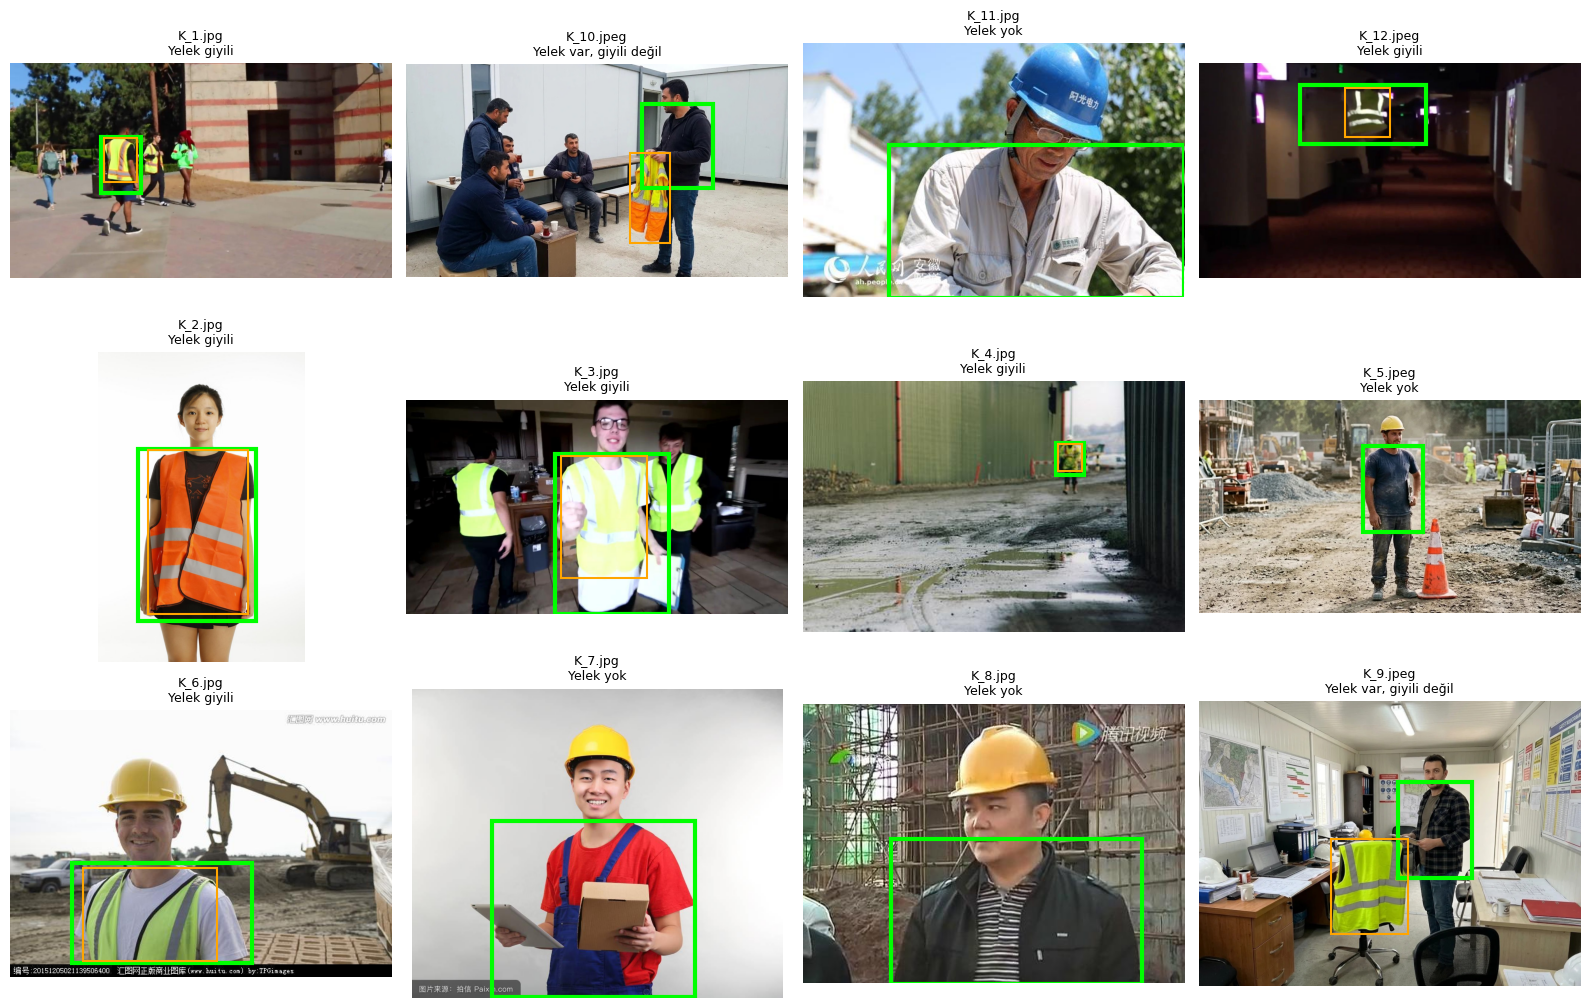

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

klasor = Path(resize_path if resize_path else path).expanduser()
cikti = Path(out_path).expanduser() if out_path else klasor

kutular = pd.read_csv(cikti / "kutular.csv", encoding="utf-8-sig")
goruntuler = pd.read_csv(cikti / "goruntuler.csv", encoding="utf-8-sig")
display(goruntuler)

eksik_sinif = goruntuler[goruntuler["dogru_sinif"].isna()]["goruntu"].tolist()
govdesiz = goruntuler[goruntuler["govde_sayisi"] == 0]["goruntu"].tolist()
acilmamis = [p.name for p in list_images(klasor) if p.name not in set(goruntuler["goruntu"])]
print("Sinifi girilmemis :", eksik_sinif or "yok")
print("Govde kutusu yok  :", govdesiz or "yok")
print("Hic acilmamis     :", acilmamis or "yok")

# kutulari goruntu uzerinde goster (her goruntuyu gozle kontrol etmek icin)
renk = {"govde": "lime", "yelek": "orange"}
isimler = goruntuler["goruntu"].tolist()
sut = 4
sat = max(1, -(-len(isimler) // sut))
fig, axes = plt.subplots(sat, sut, figsize=(4 * sut, 3.4 * sat))
axes = [axes] if sat * sut == 1 else axes.ravel()
for ax in axes:
    ax.axis("off")
for ax, isim in zip(axes, isimler):
    img = imread_u(klasor / isim)
    if img is None:
        continue
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    for _, b in kutular[kutular["goruntu"] == isim].iterrows():
        kalin = 3 if b["secilen_kisi"] == 1 else 1.5
        ax.add_patch(plt.Rectangle((b["x1"], b["y1"]), b["x2"] - b["x1"], b["y2"] - b["y1"],
                                   fill=False, edgecolor=renk[b["etiket"]], linewidth=kalin))
    sinif = goruntuler.loc[goruntuler["goruntu"] == isim, "dogru_sinif"].iloc[0]
    ax.set_title(f"{isim}\n{sinif if isinstance(sinif, str) else '- sinif yok -'}", fontsize=9)
plt.tight_layout()
plt.show()
